In [ ]:
!pip install rasterio

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import required libraries
import geopandas as gpd
import rasterio as rio
from rasterio.plot import show
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings

In [ ]:
file_path = '/content/drive/MyDrive/Flood_Susceptibility/flood_invent_400.shp'
points = gpd.read_file(file_path)
points.head(10)

,id,grid_code,geometry
0,1,0,POINT (648293.817 1116408.852)
1,2,0,POINT (648401.005 1117212.764)
2,3,0,POINT (649472.887 1114693.841)
3,4,0,POINT (650330.393 1113193.206)
4,5,0,POINT (651080.711 1114318.682)
5,6,0,POINT (651723.84 1115551.347)
6,7,0,POINT (652742.128 1115819.317)
7,8,0,POINT (652045.404 1114050.712)
8,9,0,POINT (647489.906 1115765.723)
9,10,0,POINT (650450.98 1120870.562)


In [ ]:
# # Remove columns 'pointid','grid_code' & 'geometry'
# points = points.drop(columns=['id'])
# points.head()

In [ ]:
# Make columns to extract the values of each predictive feature.
points['Relief'] = np.nan  # Initialize with NaN for floating-point values
points['Slope'] = np.nan
points['Dis_River'] = np.nan
points['Drai_Density'] = np.nan
points['TWI'] = np.nan
points['LULC'] = np.nan
points['Geomorphology'] = np.nan
points['SPI'] = np.nan
points['Conv_Index'] = np.nan
points['Curvature'] = np.nan
points['TPI'] = np.nan
points['NDVI'] = np.nan
points['Rainfall'] = np.nan

points.head()

,id,grid_code,geometry,Relief,Slope,Dis_River,Drai_Density,TWI,LULC,Geomorphology,SPI,Conv_Index,Curvature,TPI,NDVI,Rainfall
0,1,0,POINT (648293.817 1116408.852),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,0,POINT (648401.005 1117212.764),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,0,POINT (649472.887 1114693.841),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,0,POINT (650330.393 1113193.206),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,0,POINT (651080.711 1114318.682),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Raster filepaths
relief = '/content/drive/MyDrive/FinalData/relief.tif'
slope = '/content/drive/MyDrive/FinalData/slope.tif'
dis_river = '/content/drive/MyDrive/FinalData/riverdist.tif'
drai_density = '/content/drive/MyDrive/FinalData/dd.tif'
twi = '/content/drive/MyDrive/FinalData/twi.tif'
lulc = '/content/drive/MyDrive/FinalData/lulc.tif'
geomorph = '/content/drive/MyDrive/FinalData/geomorphology.tif'
spi = '/content/drive/MyDrive/FinalData/spi.tif'
conv_index = '/content/drive/MyDrive/FinalData/ci.tif'
curvature = '/content/drive/MyDrive/FinalData/curvature.tif'
tpi = '/content/drive/MyDrive/FinalData/tpi.tif'
ndvi = '/content/drive/MyDrive/FinalData/ndvi.tif'
rainfall = '/content/drive/MyDrive/FinalData/rainfall.tif'

In [ ]:
# Print the shape of each rasters
rasters = [relief, slope, dis_river, drai_density, twi,
           lulc, geomorph, spi, conv_index, curvature,
           tpi, ndvi,rainfall]
for raster in rasters:
    with rio.open(raster) as src:
        print(f"Raster: {raster}, Shape: {src.shape}")

Raster: /content/drive/MyDrive/FinalData/relief.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/slope.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/riverdist.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/dd.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/twi.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/lulc.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/geomorphology.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/spi.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/ci.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/curvature.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/tpi.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/ndvi.tif, Shape: (978, 1377)
Raster: /content/drive/MyDrive/FinalData/rainfall.tif, Shape: (978, 1377)


**Make all the raster shapes equal**

In [ ]:
import os
import rasterio
import numpy as np
from rasterio.transform import from_bounds
from rasterio.windows import Window

# Define input raster file paths (assuming these variables are already defined)
raster_files = [relief, slope, dis_river, drai_density, twi,
                lulc, geomorph, spi, conv_index, curvature,
                tpi, ndvi,rainfall]

# Define the output directory for cropped rasters
output_dir = "/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized"
os.makedirs(output_dir, exist_ok=True)  # Create the folder if it doesn't exist

# Determine the minimum dimensions across all rasters
min_rows, min_cols = float('inf'), float('inf')

for raster_file in raster_files:
    with rasterio.open(raster_file) as src:
        rows, cols = src.shape
        min_rows = min(min_rows, rows)
        min_cols = min(min_cols, cols)

print(f"Min rows: {min_rows}, Min cols: {min_cols}")

# Function to crop/standardize raster to minimum dimensions
def standardize_raster(input_raster, output_raster, min_rows, min_cols):
    with rasterio.open(input_raster) as src:
        # Calculate the window for cropping
        current_rows, current_cols = src.shape
        row_offset = (current_rows - min_rows) // 2
        col_offset = (current_cols - min_cols) // 2

        # Define the window to read
        window = Window(col_offset, row_offset, min_cols, min_rows)

        # Read the subset of the data
        data = src.read(1, window=window)

        # Update the transform for the new bounds
        transform = src.window_transform(window)

        # Update metadata for the new raster
        meta = src.meta.copy()
        meta.update({
            "height": min_rows,
            "width": min_cols,
            "transform": transform,
        })

        # Write the standardized raster to the specified output path
        with rasterio.open(output_raster, "w", **meta) as dst:
            dst.write(data, 1)

# Apply standardization to all rasters and save to the output directory
for raster_file in raster_files:
    # Extract the filename from the full path
    filename = os.path.basename(raster_file)
    # Construct the full output path in the desired folder
    output_path = os.path.join(output_dir, filename)
    standardize_raster(raster_file, output_path, min_rows, min_cols)
    print(f"Standardized raster saved: {output_path}")

Min rows: 978, Min cols: 1377
Standardized raster saved: /content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/relief.tif
Standardized raster saved: /content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/slope.tif
Standardized raster saved: /content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/riverdist.tif
Standardized raster saved: /content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/dd.tif
Standardized raster saved: /content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/twi.tif
Standardized raster saved: /content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/lulc.tif
Standardized raster saved: /content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/geomorphology.tif
Standardized raster saved: /content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/spi.tif
Standardized raster saved: /content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/ci.tif
Standardized raster saved: /content/drive/MyDrive/

In [ ]:
# Raster filepaths
relief = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/relief.tif'
slope = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/slope.tif'
dis_river = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/riverdist.tif'
drai_density = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/dd.tif'
twi = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/twi.tif'
lulc = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/lulc.tif'
geomorph = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/geomorphology.tif'
spi = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/spi.tif'
conv_index = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/ci.tif'
curvature = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/curvature.tif'
tpi = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/tpi.tif'
ndvi = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/ndvi.tif'
rainfall = '/content/drive/MyDrive/Flood_Susceptibility/DL_Data_Standardized/rainfall.tif'

In [ ]:
# Open the predictive features (raster images) using rasterio.
relief_raster = rio.open(relief)
slope_raster = rio.open(slope)
dis_river_raster = rio.open(dis_river)
drai_density_raster = rio.open(drai_density)
twi_raster = rio.open(twi)
lulc_raster = rio.open(lulc)
geomorph_raster = rio.open(geomorph)
spi_raster = rio.open(spi)
conv_index_raster = rio.open(conv_index)
curvature_raster = rio.open(curvature)
tpi_raster = rio.open(tpi)
ndvi_raster = rio.open(ndvi)
rainfall_raster = rio.open(rainfall)

In [ ]:
# convert predictive Raster layers into Numpy array.
relief_arr = relief_raster.read(1)
slope_arr = slope_raster.read(1)
dis_river_arr = dis_river_raster.read(1)
drai_density_arr = drai_density_raster.read(1)
twi_arr = twi_raster.read(1)
lulc_arr = lulc_raster.read(1)
geomorph_arr = geomorph_raster.read(1)
spi_arr = spi_raster.read(1)
conv_index_arr = conv_index_raster.read(1)
curvature_arr = curvature_raster.read(1)
tpi_arr = tpi_raster.read(1)
ndvi_arr = ndvi_raster.read(1)
rainfall_arr = rainfall_raster.read(1)

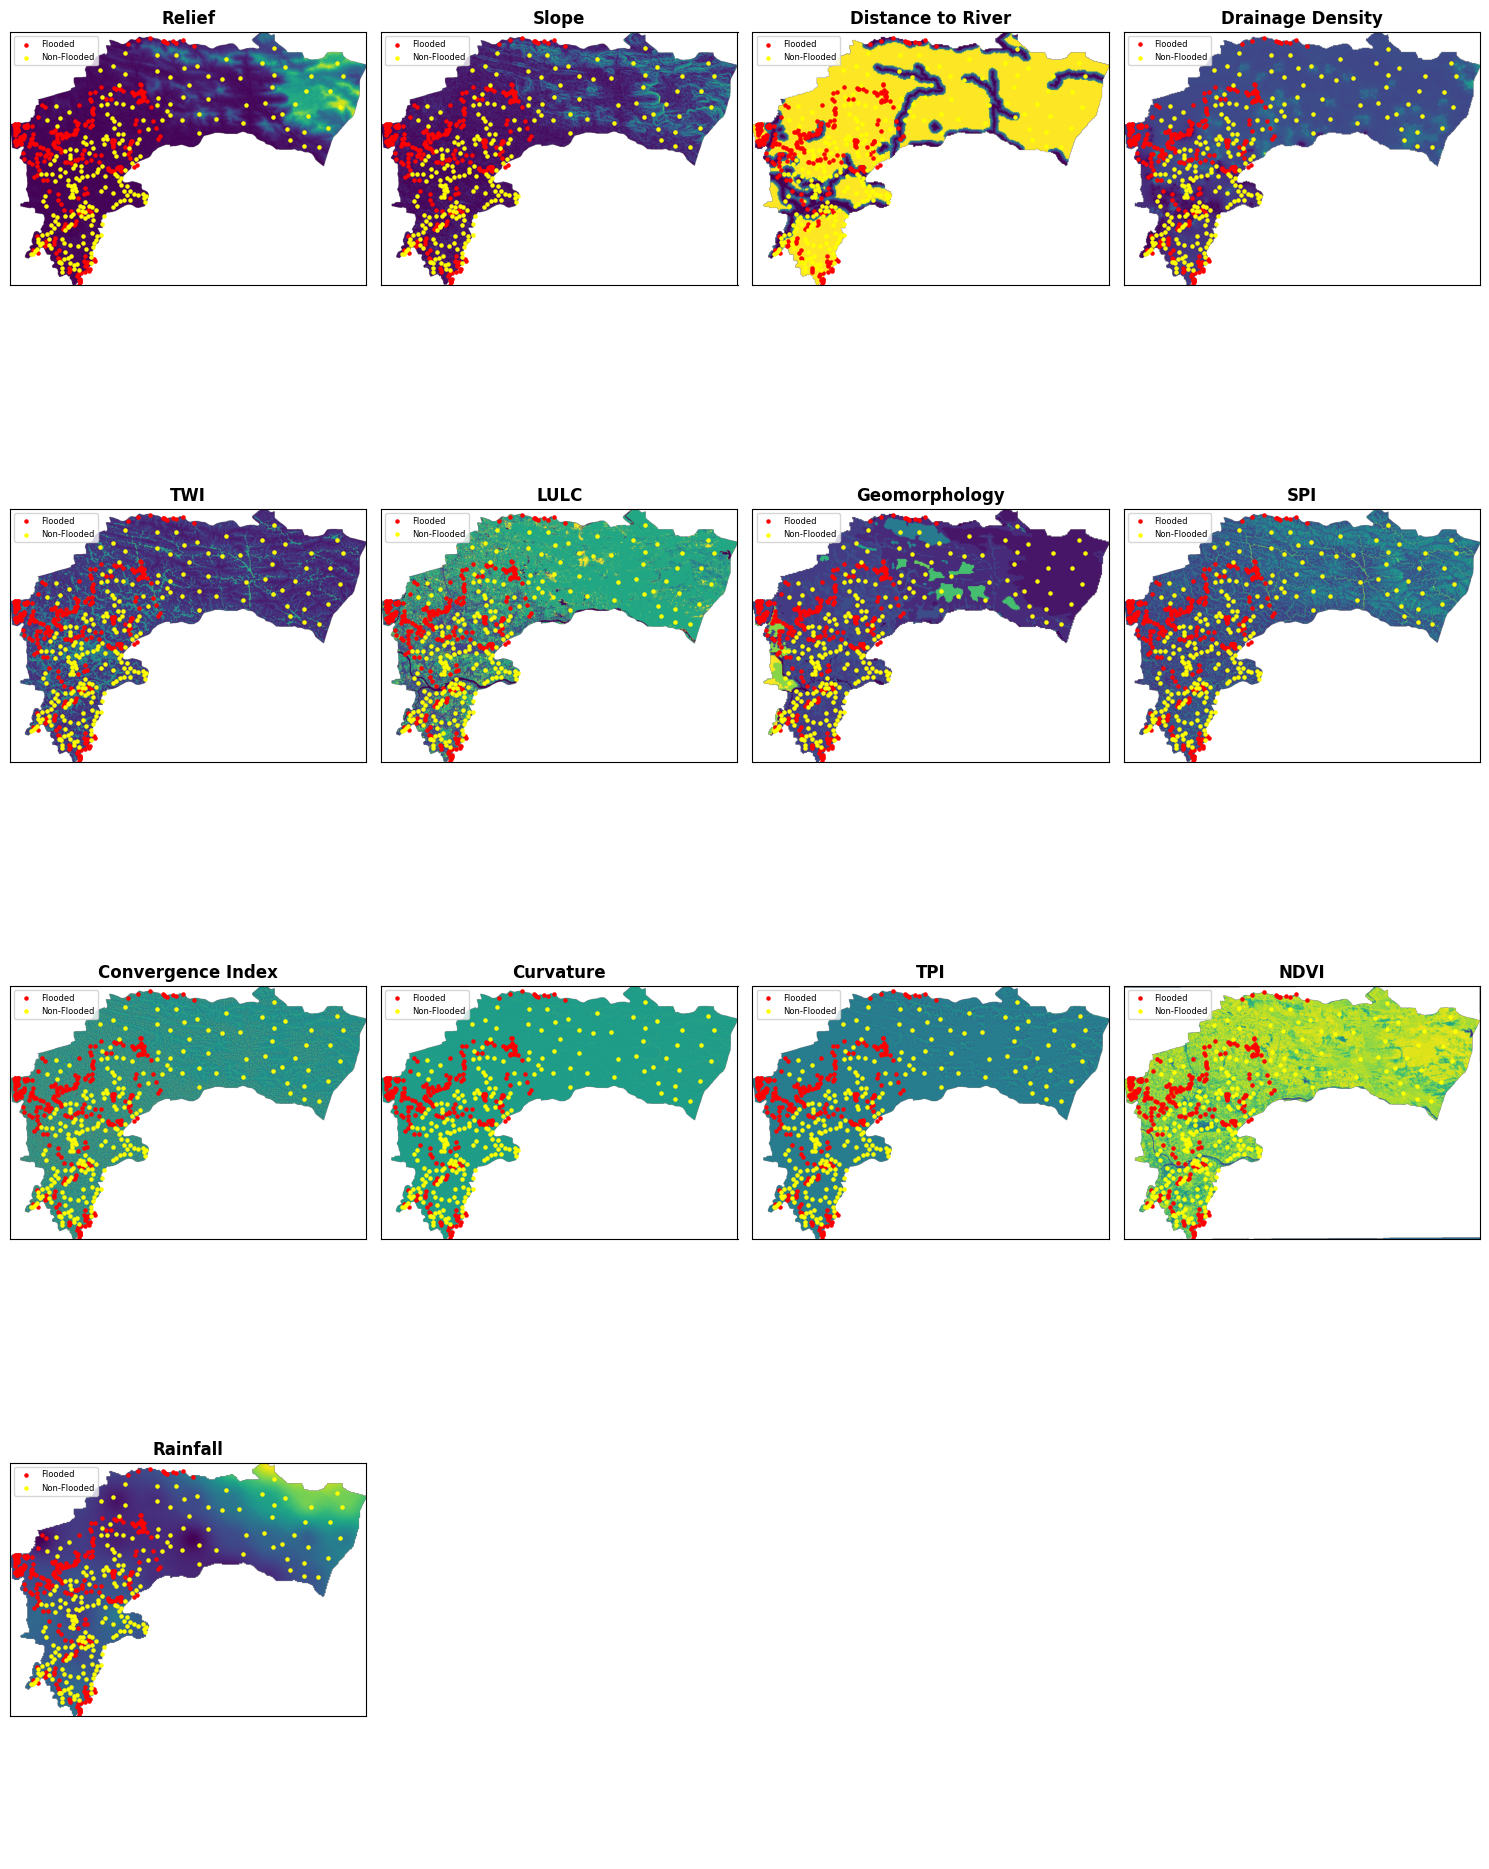

In [ ]:
# Suppress warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

# List of raster layers
rasters = [relief_raster, slope_raster, dis_river_raster,
           drai_density_raster, twi_raster, lulc_raster, geomorph_raster,
           spi_raster, conv_index_raster, curvature_raster, tpi_raster, ndvi_raster, rainfall_raster]

# Titles for each raster
raster_titles = ["Relief", "Slope", "Distance to River", "Drainage Density", "TWI",
                 "LULC", "Geomorphology", "SPI", "Convergence Index",
                 "Curvature", "TPI", "NDVI","Rainfall"]

# Separate flooded and non-flooded points
flooded_points = points[points['grid_code'] == 1]  # Points where GRIDCODE == 1
non_flooded_points = points[points['grid_code'] == 0]  # Points where GRIDCODE == 0

# Create subplots
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(15, 20))
axes = axes.flatten()  # Flatten axes for easy iteration

# Plot each raster with points overlaid
for idx, (raster, title) in enumerate(zip(rasters, raster_titles)):
    ax = axes[idx]  # Get the corresponding axis
    show(raster, ax=ax, title=title, cmap='viridis')  # Plot the raster

    # Overlay flooded points in red and non-flooded points in green
    flooded_points.plot(ax=ax, color='red', markersize=5, label='Flooded')
    non_flooded_points.plot(ax=ax, color='yellow', markersize=5, label='Non-Flooded')

    ax.legend(loc='upper left', fontsize=6)  # Add legend for points
    ax.set_xticks([])
    ax.set_yticks([])


# Turn off unused axes if there are any
for ax in axes[len(rasters):]:
    ax.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# Initialize columns with NaN to avoid dtype issues
warnings.filterwarnings("ignore", category=RuntimeWarning)
columns = ['Relief', 'Slope', 'Dis_River', 'Drai_Density', 'TWI', 'LULC',
           'Geomorphology', 'SPI', 'Conv_Index', 'Curvature', 'TPI', 'NDVI','Rainfall']
for col in columns:
    points[col] = np.nan

# Iterate over the rows to extract raster values
for index, row in points.iterrows():  # iterate over the rows in the shapefile.
    longitude = row['geometry'].x  # Get the longitude of the point.
    latitude = row['geometry'].y  # Get the latitude of the point.

    # Find the corresponding raster cell
    rowIndex, colIndex = relief_raster.index(longitude, latitude)

    # Assign values to columns explicitly using loc
    points.loc[index, 'Relief'] = relief_arr[rowIndex, colIndex]
    points.loc[index, 'Slope'] = slope_arr[rowIndex, colIndex]
    points.loc[index, 'Dis_River'] = dis_river_arr[rowIndex, colIndex]
    points.loc[index, 'Drai_Density'] = drai_density_arr[rowIndex, colIndex]
    points.loc[index, 'TWI'] = twi_arr[rowIndex, colIndex]
    points.loc[index, 'LULC'] = lulc_arr[rowIndex, colIndex]
    points.loc[index, 'Geomorphology'] = geomorph_arr[rowIndex, colIndex]
    points.loc[index, 'SPI'] = spi_arr[rowIndex, colIndex]
    points.loc[index, 'Conv_Index'] = conv_index_arr[rowIndex, colIndex]
    points.loc[index, 'Curvature'] = curvature_arr[rowIndex, colIndex]
    points.loc[index, 'TPI'] = tpi_arr[rowIndex, colIndex]
    points.loc[index, 'NDVI'] = ndvi_arr[rowIndex, colIndex]
    points.loc[index, 'Rainfall'] = rainfall_arr[rowIndex, colIndex]

# Check the updated GeoDataFrame
points.head()


,id,grid_code,geometry,Relief,Slope,Dis_River,Drai_Density,TWI,LULC,Geomorphology,SPI,Conv_Index,Curvature,TPI,NDVI,Rainfall
0,1,0,POINT (648293.817 1116408.852),21.0,7.210669,1000.0,0.567845,5.603608,1.0,4.0,5.040757,34.478920,0.333333,2.405406,0.272727,2458.048096
1,2,0,POINT (648401.005 1117212.764),14.0,5.139694,1000.0,0.444897,10.679511,1.0,4.0,7.578450,-20.343735,-0.444444,-1.729730,0.211433,2446.077881
2,3,0,POINT (649472.887 1114693.841),32.0,4.380487,1000.0,0.676938,5.948130,1.0,4.0,4.632522,1.221863,0.333333,2.324324,0.578451,2490.737305
3,4,0,POINT (650330.393 1113193.206),29.0,3.945476,1000.0,0.793863,7.326543,3.0,4.0,6.156691,48.258034,0.111111,1.486486,0.776360,2553.509277
4,5,0,POINT (651080.711 1114318.682),12.0,1.909152,1000.0,0.743280,7.876605,5.0,4.0,4.476785,-50.000000,-0.555556,-1.081081,0.511879,2492.831543


In [ ]:
# Save the points filecontent/drive/MyDr
points.to_file('/content/drive/MyDrive/Flood_Susceptibility/New_Inventory/flood_invent_400.shp') # save as a shapfile

/tmp/ipykernel_355/1181022744.py:2: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  points.to_file('/content/drive/MyDrive/Flood_Susceptibility/New_Inventory/flood_invent_400.shp') # save as a shapfile
